# пр 1

In [3]:
import pandas as pd
import numpy as np

# Назви колонок згідно з офіційною документацією датасету
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

# Зчитуємо дані. Зверни увагу, що пропуски в цьому датасеті зазвичай позначені знаком '?'
# Тому ми одразу кажемо pandas вважати '?' за NaN (порожнє значення)
df = pd.read_csv(r'C:\Users\UserComp\Downloads\heart+disease\processed.cleveland.data', names=column_names, na_values='?')

# Дивимось на перші 5 рядків
print(df.head())
print(df.info())
print(df.describe())
print(df.isnull().sum())

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   

   slope   ca  thal  target  
0    3.0  0.0   6.0       0  
1    2.0  3.0   3.0       2  
2    2.0  2.0   7.0       1  
3    3.0  0.0   3.0       0  
4    1.0  0.0   3.0       0  
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null  

In [4]:
# Перевірка на дублікати
print("Кількість повних дублікатів:", df.duplicated().sum())

# Перевірка унікальних значень категорій (щоб переконатись, що немає дивних записів)
for col in ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']:
    print(f"{col}: {df[col].unique()}")

Кількість повних дублікатів: 0
sex: [1. 0.]
cp: [1. 4. 3. 2.]
fbs: [1. 0.]
restecg: [2. 0. 1.]
exang: [0. 1.]
slope: [3. 2. 1.]
ca: [ 0.  3.  2.  1. nan]
thal: [ 6.  3.  7. nan]


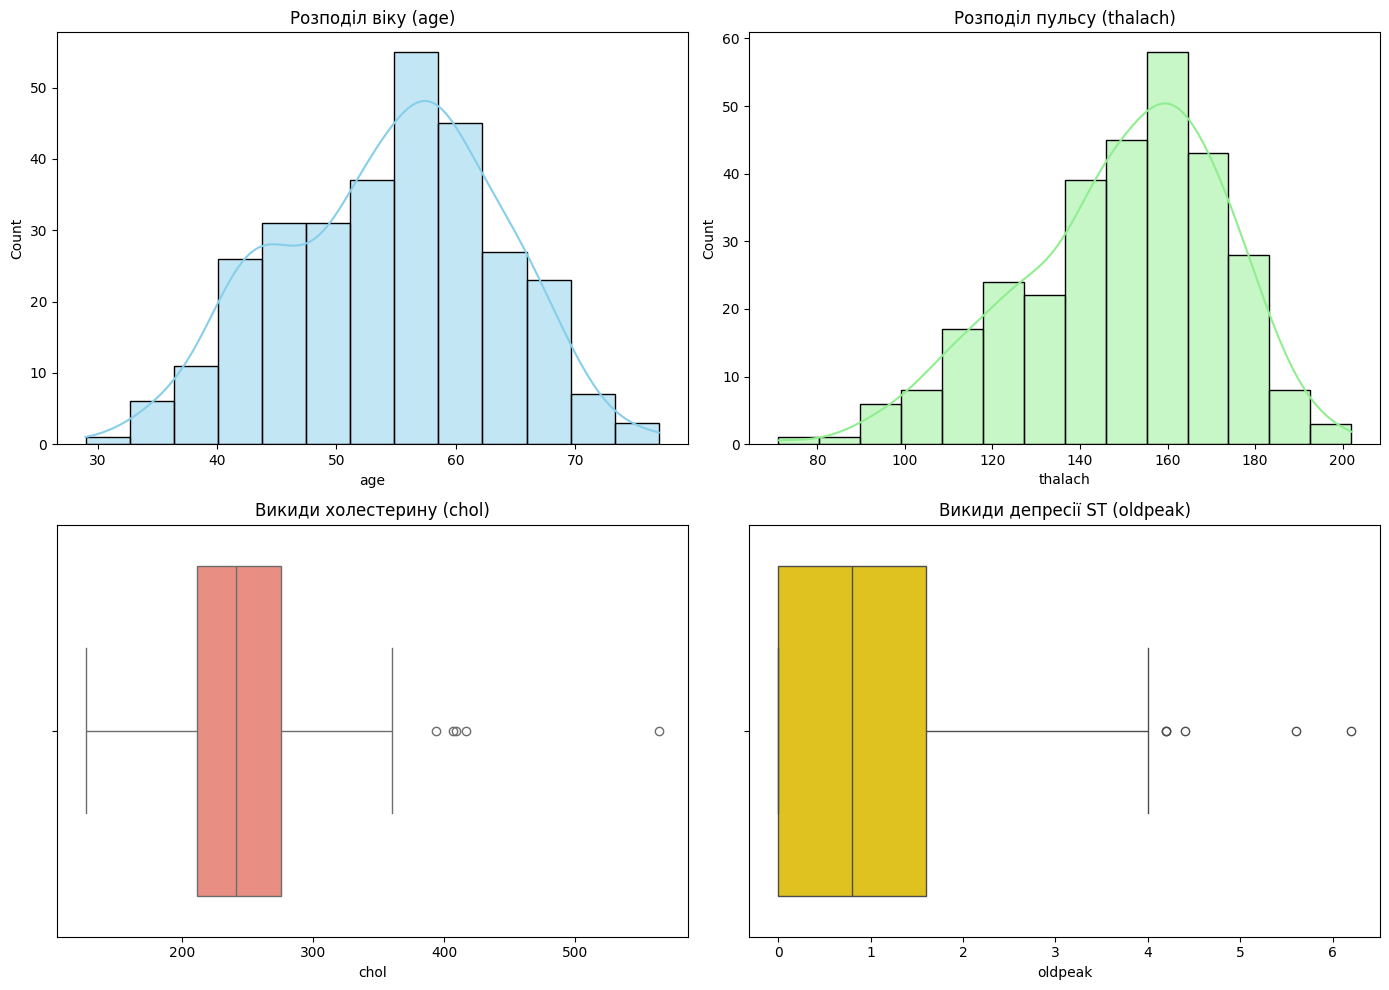

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Налаштовуємо загальний розмір полотна
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Гістограма для віку
sns.histplot(df['age'], kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Розподіл віку (age)')

# 2. Гістограма для макс. пульсу
sns.histplot(df['thalach'], kde=True, ax=axes[0, 1], color='lightgreen')
axes[0, 1].set_title('Розподіл пульсу (thalach)')

# 3. Boxplot для холестерину (шукаємо аномалії)
sns.boxplot(x=df['chol'], ax=axes[1, 0], color='salmon')
axes[1, 0].set_title('Викиди холестерину (chol)')

# 4. Boxplot для oldpeak (шукаємо аномалії)
sns.boxplot(x=df['oldpeak'], ax=axes[1, 1], color='gold')
axes[1, 1].set_title('Викиди депресії ST (oldpeak)')

plt.tight_layout()
plt.show()

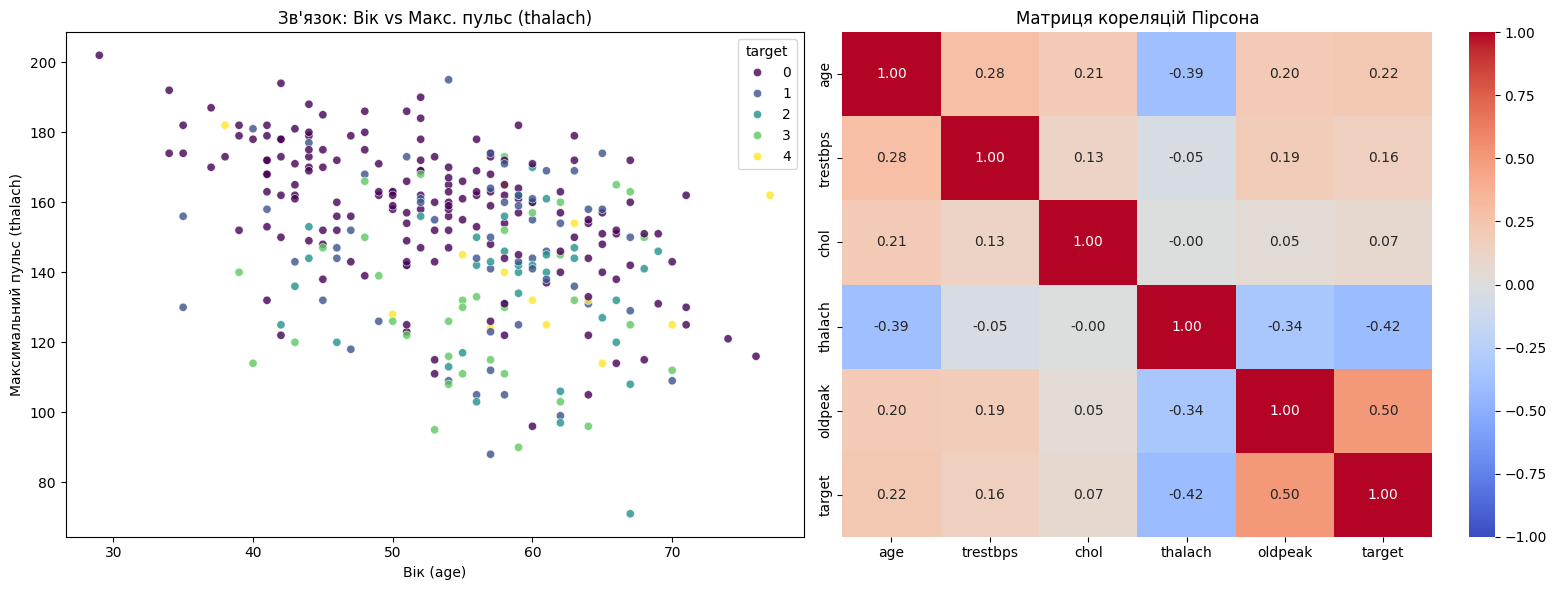

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Виділяємо справжні числові ознаки + target для кореляції
num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'target']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatterplot: Зв'язок між віком та пульсом
# hue='target' розфарбує точки залежно від наявності хвороби
sns.scatterplot(data=df, x='age', y='thalach', hue='target', palette='viridis', ax=axes[0], alpha=0.8)
axes[0].set_title("Зв'язок: Вік vs Макс. пульс (thalach)")
axes[0].set_xlabel("Вік (age)")
axes[0].set_ylabel("Максимальний пульс (thalach)")

# 2. Кореляційна матриця (Heatmap)
corr_matrix = df[num_features].corr(method='pearson')
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', ax=axes[1], vmin=-1, vmax=1, center=0)
axes[1].set_title("Матриця кореляцій Пірсона")

plt.tight_layout()
plt.show()

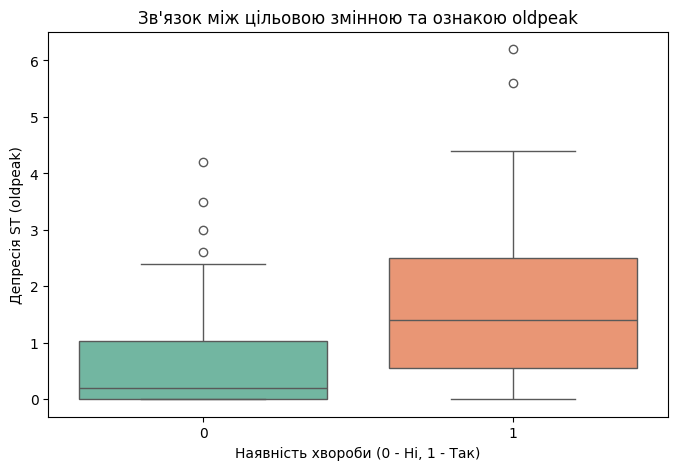

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Створюємо тимчасову колонку з бінарним таргетом для красивого графіка
df['target_binary'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

plt.figure(figsize=(8, 5))
sns.boxplot(x='target_binary', y='oldpeak', data=df, hue='target_binary', palette='Set2', legend=False)
plt.title("Зв'язок між цільовою змінною та ознакою oldpeak")
plt.xlabel("Наявність хвороби (0 - Ні, 1 - Так)")
plt.ylabel("Депресія ST (oldpeak)")
plt.show()

# Після побудови графіка тимчасову колонку можна видалити
df = df.drop('target_binary', axis=1)




C:\Users\UserComp\AppData\Local\Temp\ipykernel_16852\1646148703.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='target_bin', y='thalach', palette='Set2', ax=axes[1])


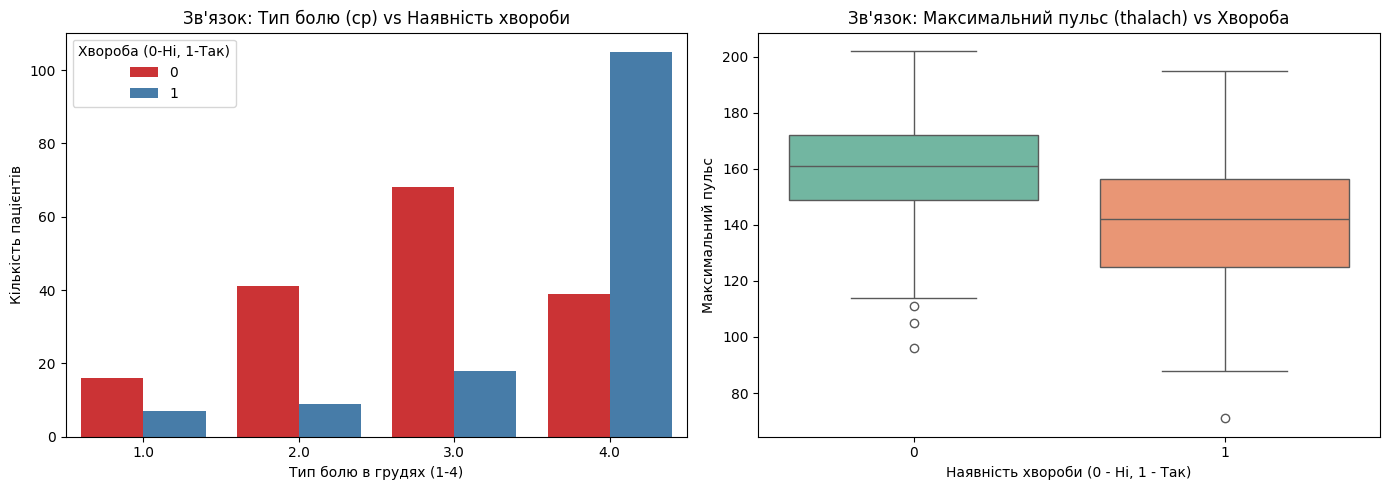

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

# Тимчасова бінаризація target для візуалізації
df['target_bin'] = df['target'].apply(lambda x: 1 if x > 0 else 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Countplot для категоріальної ознаки (Тип болю в грудях)
sns.countplot(data=df, x='cp', hue='target_bin', palette='Set1', ax=axes[0])
axes[0].set_title("Зв'язок: Тип болю (cp) vs Наявність хвороби")
axes[0].set_xlabel("Тип болю в грудях (1-4)")
axes[0].set_ylabel("Кількість пацієнтів")
axes[0].legend(title='Хвороба (0-Ні, 1-Так)')

# 2. Boxplot для числової ознаки (Макс. пульс)
sns.boxplot(data=df, x='target_bin', y='thalach', palette='Set2', ax=axes[1])
axes[1].set_title("Зв'язок: Максимальний пульс (thalach) vs Хвороба")
axes[1].set_xlabel("Наявність хвороби (0 - Ні, 1 - Так)")
axes[1].set_ylabel("Максимальний пульс")

plt.tight_layout()
plt.show()

# Видаляємо тимчасову колонку
df = df.drop('target_bin', axis=1)

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
df = pd.read_csv(r'C:\Users\UserComp\Downloads\heart+disease\processed.cleveland.data', names=column_names, na_values='?')
# 1. Підготовка цільової змінної (бінаризація)
X = df.drop('target', axis=1)
y = df['target'].apply(lambda x: 1 if x > 0 else 0)

# 2. Розбиття на train та test (ДО будь-якого препроцесингу!)
# stratify=y гарантує, що пропорція хворих/здорових буде однаковою в обох вибірках
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Розподіл ознак по групах згідно з нашим планом
num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_features = ['cp', 'restecg', 'slope', 'thal', 'ca']
bin_features = ['sex', 'fbs', 'exang'] # Бінарні залишаємо як є

# 4. Створення окремих кроків (Pipeline) для числових та категоріальних даних
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# 5. Об'єднання в єдиний ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features),
        ('bin', 'passthrough', bin_features)
    ])

# 6. Застосування preprocessor
# ВАЖЛИВО: fit_transform тільки для X_train! Для X_test - лише transform!
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Виведення результатів для перевірки (пункт методички "Перевірка підготовленого набору даних")
print(f"Розмірність X_train ДО обробки: {X_train.shape}")
print(f"Розмірність X_train ПІСЛЯ обробки: {X_train_processed.shape}")
print(f"Розмірність X_test ПІСЛЯ обробки: {X_test_processed.shape}")

# Перевірка на наявність пропусків після обробки
import numpy as np
print(f"Кількість пропусків у X_train_processed: {np.isnan(X_train_processed).sum()}")

# Витягуємо нові назви колонок з ColumnTransformer
new_feature_names = preprocessor.get_feature_names_out()

print("Назви ознак після попередньої обробки:")
for i, name in enumerate(new_feature_names):
    print(f"{i+1}. {name}")

Розмірність X_train ДО обробки: (242, 13)
Розмірність X_train ПІСЛЯ обробки: (242, 25)
Розмірність X_test ПІСЛЯ обробки: (61, 25)
Кількість пропусків у X_train_processed: 0
Назви ознак після попередньої обробки:
1. num__age
2. num__trestbps
3. num__chol
4. num__thalach
5. num__oldpeak
6. cat__cp_1.0
7. cat__cp_2.0
8. cat__cp_3.0
9. cat__cp_4.0
10. cat__restecg_0.0
11. cat__restecg_1.0
12. cat__restecg_2.0
13. cat__slope_1.0
14. cat__slope_2.0
15. cat__slope_3.0
16. cat__thal_3.0
17. cat__thal_6.0
18. cat__thal_7.0
19. cat__ca_0.0
20. cat__ca_1.0
21. cat__ca_2.0
22. cat__ca_3.0
23. bin__sex
24. bin__fbs
25. bin__exang


# лр 1

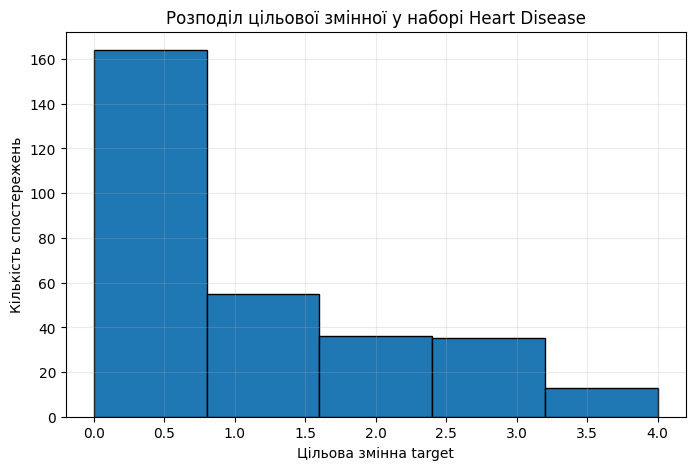

=== Результати крос-валідації ===
            Model  CV_RMSE_mean  CV_RMSE_std
0        Baseline      1.206953     0.094173
1          Linear      0.848172     0.123274
2  Polynomial d=2     16.168830    11.044225
3           Ridge      0.841490     0.125488


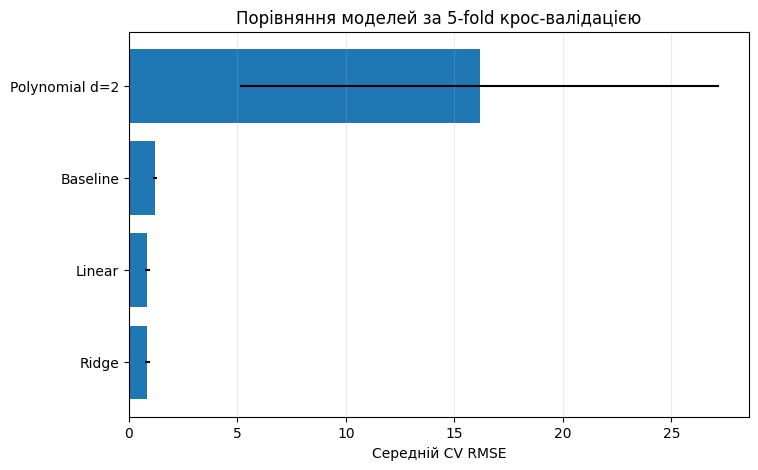


=== Оцінювання фінальної моделі на тестовій вибірці ===
MAE  - 0.6512
RMSE - 0.8383
R2   - 0.5772


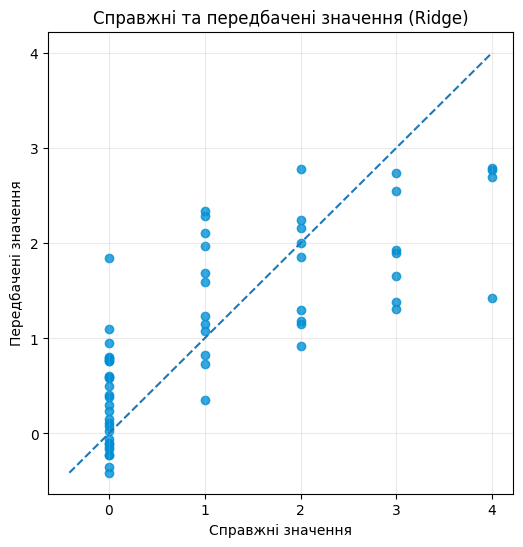

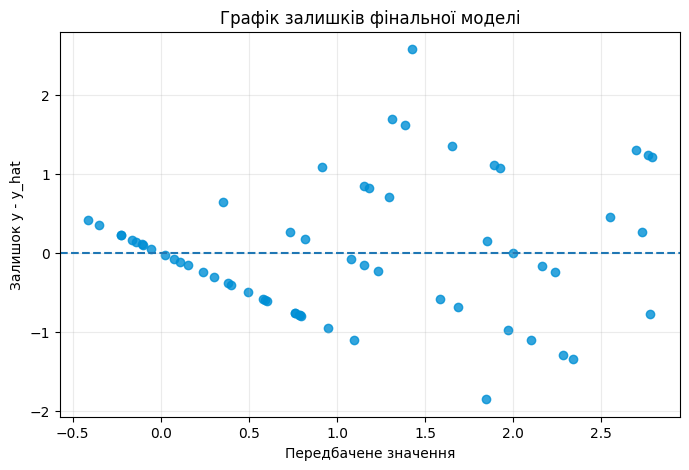


=== Найбільші похибки моделі ===
     actual  predicted  abs_error
45        4   1.423354   2.576646
92        0   1.847149   1.847149
109       3   1.310967   1.689033
228       3   1.386016   1.613984
137       3   1.652765   1.347235


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, PolynomialFeatures
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# === 1. Первинний аналіз цільової змінної ===
# Будуємо гістограму цільової змінної (як у прикладі)
plt.figure(figsize=(8, 5))
plt.hist(df['target'], bins=5, edgecolor='black', color='#1f77b4')
plt.xlabel('Цільова змінна target')
plt.ylabel('Кількість спостережень')
plt.title('Розподіл цільової змінної у наборі Heart Disease')
plt.grid(alpha=0.25)
plt.show()

# === 2. Формування простору ознак та розбиття ===
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42
)

# === 3. Попередня обробка (Pipeline) ===
num_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
cat_features = ['cp', 'restecg', 'slope', 'thal', 'ca']
bin_features = ['sex', 'fbs', 'exang']

num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features),
    ('bin', 'passthrough', bin_features)
])

# === 4. Побудова моделей ===
baseline = Pipeline([
    ('prep', preprocessor), 
    ('model', DummyRegressor(strategy='mean'))
])

linear_model = Pipeline([
    ('prep', preprocessor), 
    ('model', LinearRegression())
])

poly2_model = Pipeline([
    ('prep', preprocessor), 
    ('poly', PolynomialFeatures(degree=2, include_bias=False)), 
    ('model', LinearRegression())
])

# Додаємо Ridge як додаткову обґрунтовану модель (замість Poly d=3, яка дає збій)
ridge_model = Pipeline([
    ('prep', preprocessor), 
    ('model', Ridge(alpha=1.0))
])

# === 5. Оцінювання моделей за допомогою крос-валідації ===
models = {
    'Baseline': baseline,
    'Linear': linear_model,
    'Polynomial d=2': poly2_model,
    'Ridge': ridge_model
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, model in models.items():
    # Використовуємо neg_root_mean_squared_error як у прикладі
    scores = cross_val_score(
        model, X_train, y_train, 
        cv=cv, 
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )
    rmse_scores = -scores
    
    results.append({
        'Model': name,
        'CV_RMSE_mean': rmse_scores.mean(),
        'CV_RMSE_std': rmse_scores.std()
    })

results_df = pd.DataFrame(results)
print("=== Результати крос-валідації ===")
print(results_df)

# Діаграма порівняння (горизонтальна, з вусами похибок, як у прикладі)
results_df = results_df.sort_values('CV_RMSE_mean', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(
    results_df['Model'], 
    results_df['CV_RMSE_mean'], 
    xerr=results_df['CV_RMSE_std'],
    color='#1f77b4'
)
plt.xlabel('Середній CV RMSE')
plt.title('Порівняння моделей за 5-fold крос-валідацією')
plt.grid(axis='x', alpha=0.25)
plt.show()

# === 6. Вибір фінальної моделі та тестування ===
# Згідно з нашими минулими результатами, Ridge показав себе найкраще і найстабільніше
final_model = ridge_model
final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n=== Оцінювання фінальної моделі на тестовій вибірці ===")
print(f"MAE  - {mae:.4f}")
print(f"RMSE - {rmse:.4f}")
print(f"R2   - {r2:.4f}")

# === 7. Порівняння справжніх та передбачених значень ===
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.8, color='#008fd5')

# Ідеальна діагональ
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())
plt.plot([min_value, max_value], [min_value, max_value], color='tab:blue', linestyle='--')

plt.xlabel('Справжні значення')
plt.ylabel('Передбачені значення')
plt.title('Справжні та передбачені значення (Ridge)')
plt.grid(alpha=0.25)
plt.show()

# === 8. Аналіз залишків ===
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.8, color='#008fd5')
plt.axhline(0, color='tab:blue', linestyle='--')

plt.xlabel('Передбачене значення')
plt.ylabel('Залишок y - y_hat')
plt.title('Графік залишків фінальної моделі')
plt.grid(alpha=0.25)
plt.show()

# === 9. Аналіз найбільших похибок ===
errors = pd.DataFrame({
    'actual': y_test,
    'predicted': y_pred
})
errors['abs_error'] = np.abs(errors['actual'] - errors['predicted'])

print("\n=== Найбільші похибки моделі ===")
print(errors.sort_values('abs_error', ascending=False).head(5))